<style>
@keyframes glow{0%,100%{text-shadow:0 0 10px #f43f5e,0 0 20px #f43f5e}50%{text-shadow:0 0 20px #fb7185,0 0 40px #fb7185}}
@keyframes slideUp{from{opacity:0;transform:translateY(20px)}to{opacity:1;transform:translateY(0)}}
@keyframes shimmer{0%{background-position:-200% center}100%{background-position:200% center}}
</style>

<div style="background:linear-gradient(135deg,#0f172a 0%,#1e1b4b 40%,#31102f 100%);padding:40px;border-radius:20px;border:1px solid #f43f5e;margin-bottom:20px;">
<h1 style="color:#e2e8f0;text-align:center;font-size:2.5em;margin-bottom:5px;animation:glow 3s ease-in-out infinite,slideUp 1s ease-out;">💳 Predicting Credit Card Fraud</h1>
<h3 style="text-align:center;font-size:1.2em;margin-top:0;background:linear-gradient(90deg,#f43f5e,#fb7185,#38bdf8,#a855f7,#f43f5e);background-size:200% auto;-webkit-background-clip:text;-webkit-text-fill-color:transparent;background-clip:text;animation:shimmer 4s linear infinite;">Playground Series — Season 6, Episode 11</h3>
<p style="color:#94a3b8;text-align:center;">Binary Classification under Extreme Imbalance · LightGBM + XGBoost + CatBoost Ensemble with Optuna HPO & Meta-Stacking</p>
<hr style="border:1px solid #f43f5e;margin:15px 50px;opacity:0.4;">
<p style="color:#94a3b8;text-align:center;font-size:0.9em;">
🎯 <b>Target:</b> is_fraud (probability) · 📏 <b>Metric:</b> ROC-AUC · 🧠 <b>Key Insights:</b> Quasi-Constant Risk Lift + OOF Target Encoding + Generalization Guard
</p>
</div>


## 📑 Table of Contents
1. [⚙️ Setup & Configuration](#setup)
2. [📥 Data Loading & Inspection](#data-loading)
3. [📊 EDA — Fraud Rates, Distributions & Quasi-Constant Risk Flags](#eda)
4. [🛠️ Feature Engineering — Risk Lift, Ratios & The String Trick](#fe)
5. [🔍 Optuna Hyperparameter Optimization](#optuna)
6. [🤖 Multi-Model 5-Fold Stratified CV Training](#training)
7. [🔮 Meta-Stacking Ensemble & Rank Blending](#stacking)
8. [🩺 Generalization Diagnostics (Overfit / Underfit Scorecard)](#diagnostics)
9. [📤 Submission & Verification](#submission)
10. [🔑 Key Takeaways](#takeaways)


<a id="setup"></a>
## ⚙️ 1. Setup & Configuration


In [1]:
# ==============================================================================
# IMPORTS
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, gc, time, warnings
from pathlib import Path

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, brier_score_loss, log_loss
)
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from scipy.stats import ks_2samp

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
import optuna
from optuna.samplers import TPESampler

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings('ignore')
print('✅ All core libraries successfully loaded.')


✅ All core libraries successfully loaded.


In [2]:
# ==============================================================================
# CONFIGURATION
# ==============================================================================
class CFG:
    SEED = 42
    N_FOLDS = 5
    EARLY_STOPPING = 150
    OPTUNA_TRIALS = 35          # Number of trials per model
    OPTUNA_TIMEOUT = 600        # 10 minutes timeout per model
    USE_GPU = True              # Accelerates XGBoost & CatBoost
    SMOOTHING = 20.0            # Smoothing parameter for OOF Target Encoding

np.random.seed(CFG.SEED)
print(f'Config initialized: {CFG.N_FOLDS} Folds | Seed={CFG.SEED} | GPU={CFG.USE_GPU}')
print(f'Optuna Tuning: {CFG.OPTUNA_TRIALS} trials per model family')


Config initialized: 5 Folds | Seed=42 | GPU=True
Optuna Tuning: 35 trials per model family


<a id="data-loading"></a>
## 📥 2. Data Loading & Inspection


In [3]:
# ==============================================================================
# DATA INGESTION — Resilient Path Detection
# ==============================================================================
CANDIDATE_PATHS = [
    '/kaggle/input/playground-series-s6e11',
    './playground-series-s6e11',
    '../input/playground-series-s6e11',
    '.'
]

INPUT_DIR = None
for p in CANDIDATE_PATHS:
    if os.path.exists(p) and os.path.exists(os.path.join(p, 'train.csv')):
        INPUT_DIR = p
        break

if INPUT_DIR is None:
    INPUT_DIR = '/kaggle/input/competitions/playground-series-s6e11'
    print(f'⚠️ Warning: Local files not found, defaulting to Kaggle path: {INPUT_DIR}')
else:
    print(f'✅ Found competition data at: {INPUT_DIR}')

train = pd.read_csv(f'{INPUT_DIR}/train.csv')
test  = pd.read_csv(f'{INPUT_DIR}/test.csv')
sample_sub = pd.read_csv(f'{INPUT_DIR}/sample_submission.csv')

TARGET = 'is_fraud'
ID_COL = 'id'

print(f'Train shape: {train.shape}')
print(f'Test shape : {test.shape}')
print(f'Sample sub : {sample_sub.shape}')

fraud_count = train[TARGET].sum()
fraud_rate = train[TARGET].mean() * 100
print(f'\nTarget Balance ({TARGET}):')
print(f'  Legitimate (0): {len(train) - fraud_count:,} ({100 - fraud_rate:.2f}%)')
print(f'  Fraudulent (1): {fraud_count:,} ({fraud_rate:.2f}%)')
print(f'  Imbalance Ratio: ~{int((100 - fraud_rate) / fraud_rate)}:1')
train.head(5)


⚠️ Warning: Local files not found, defaulting to Kaggle path: /kaggle/input/competitions/playground-series-s6e11
Train shape: (699960, 26)
Test shape : (299984, 25)
Sample sub : (299984, 2)

Target Balance (is_fraud):
  Legitimate (0): 688,271.0 (98.33%)
  Fraudulent (1): 11,689.0 (1.67%)
  Imbalance Ratio: ~58:1


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


<a id="eda"></a>
## 📊 3. EDA — Fraud Rates, Distributions & Quasi-Constant Risk Flags


In [4]:
# ==============================================================================
# EDA — Missing Value Check
# ==============================================================================
miss_train = train.drop(columns=[ID_COL, TARGET]).isnull().mean() * 100
miss_test  = test.drop(columns=[ID_COL]).isnull().mean() * 100

miss_df = pd.DataFrame({'Train Missing %': miss_train, 'Test Missing %': miss_test})
miss_nonzero = miss_df[(miss_df['Train Missing %'] > 0) | (miss_df['Test Missing %'] > 0)]

if len(miss_nonzero) > 0:
    print('⚠️ Missing values detected:')
    print(miss_nonzero)
else:
    print('✅ Zero missing values across all features in Train and Test datasets!')


✅ Zero missing values across all features in Train and Test datasets!


🚨 RISK LIFT FACTORS FOR SPARSE FLAGS:


,Risk Flag,Positive Count,Positive %,Conditional Fraud Rate %,Risk Lift Factor
3,ip_country_mismatch,11312,1.62%,16.50%,9.88x
5,is_ai_generated_scam_attempt,2299,0.33%,15.22%,9.12x
4,billing_shipping_mismatch,9054,1.29%,12.99%,7.78x
0,is_foreign_transaction,12098,1.73%,12.57%,7.53x
2,used_vpn,23665,3.38%,6.55%,3.92x
1,is_new_merchant,106720,15.25%,4.73%,2.83x


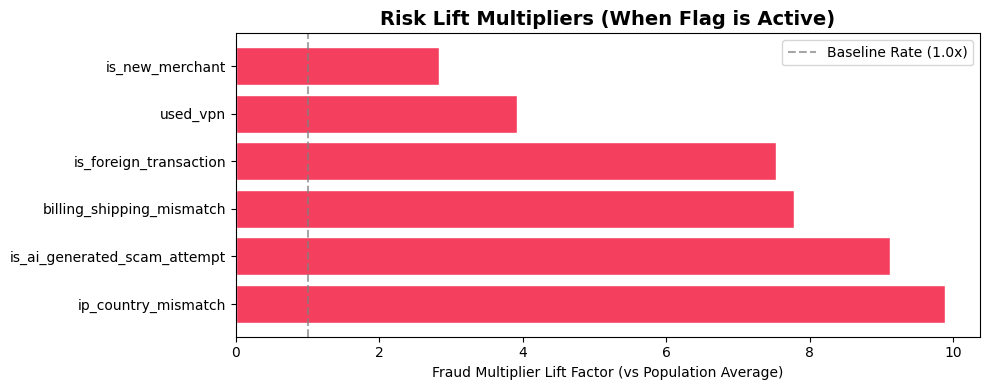

In [5]:
# ==============================================================================
# EDA — The "Quasi-Constant" Paradox: Risk Lift Analysis
# ==============================================================================
# The sparse boolean flags (>98% zeros) look like noise to automated pruning,
# but when True, their conditional fraud rate spikes dramatically!
risk_flags = [
    'is_foreign_transaction', 'is_new_merchant', 'used_vpn',
    'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt'
]
available_flags = [f for f in risk_flags if f in train.columns]

base_rate = train[TARGET].mean()
lift_records = []

for flag in available_flags:
    pos_subset = train[train[flag] == 1]
    if len(pos_subset) > 0:
        cond_rate = pos_subset[TARGET].mean()
        lift = cond_rate / (base_rate + 1e-8)
        lift_records.append({
            'Risk Flag': flag,
            'Positive Count': len(pos_subset),
            'Positive %': len(pos_subset) / len(train) * 100,
            'Conditional Fraud Rate %': cond_rate * 100,
            'Risk Lift Factor': lift
        })

lift_df = pd.DataFrame(lift_records).sort_values('Risk Lift Factor', ascending=False)
print('🚨 RISK LIFT FACTORS FOR SPARSE FLAGS:')
display(lift_df.style.format({
    'Positive %': '{:.2f}%',
    'Conditional Fraud Rate %': '{:.2f}%',
    'Risk Lift Factor': '{:.2f}x'
}))

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(lift_df['Risk Flag'], lift_df['Risk Lift Factor'], color='#f43f5e', edgecolor='white')
ax.axvline(1.0, color='gray', linestyle='--', alpha=0.7, label='Baseline Rate (1.0x)')
ax.set_title('Risk Lift Multipliers (When Flag is Active)', fontsize=14, fontweight='bold')
ax.set_xlabel('Fraud Multiplier Lift Factor (vs Population Average)')
ax.legend()
plt.tight_layout()
plt.show()


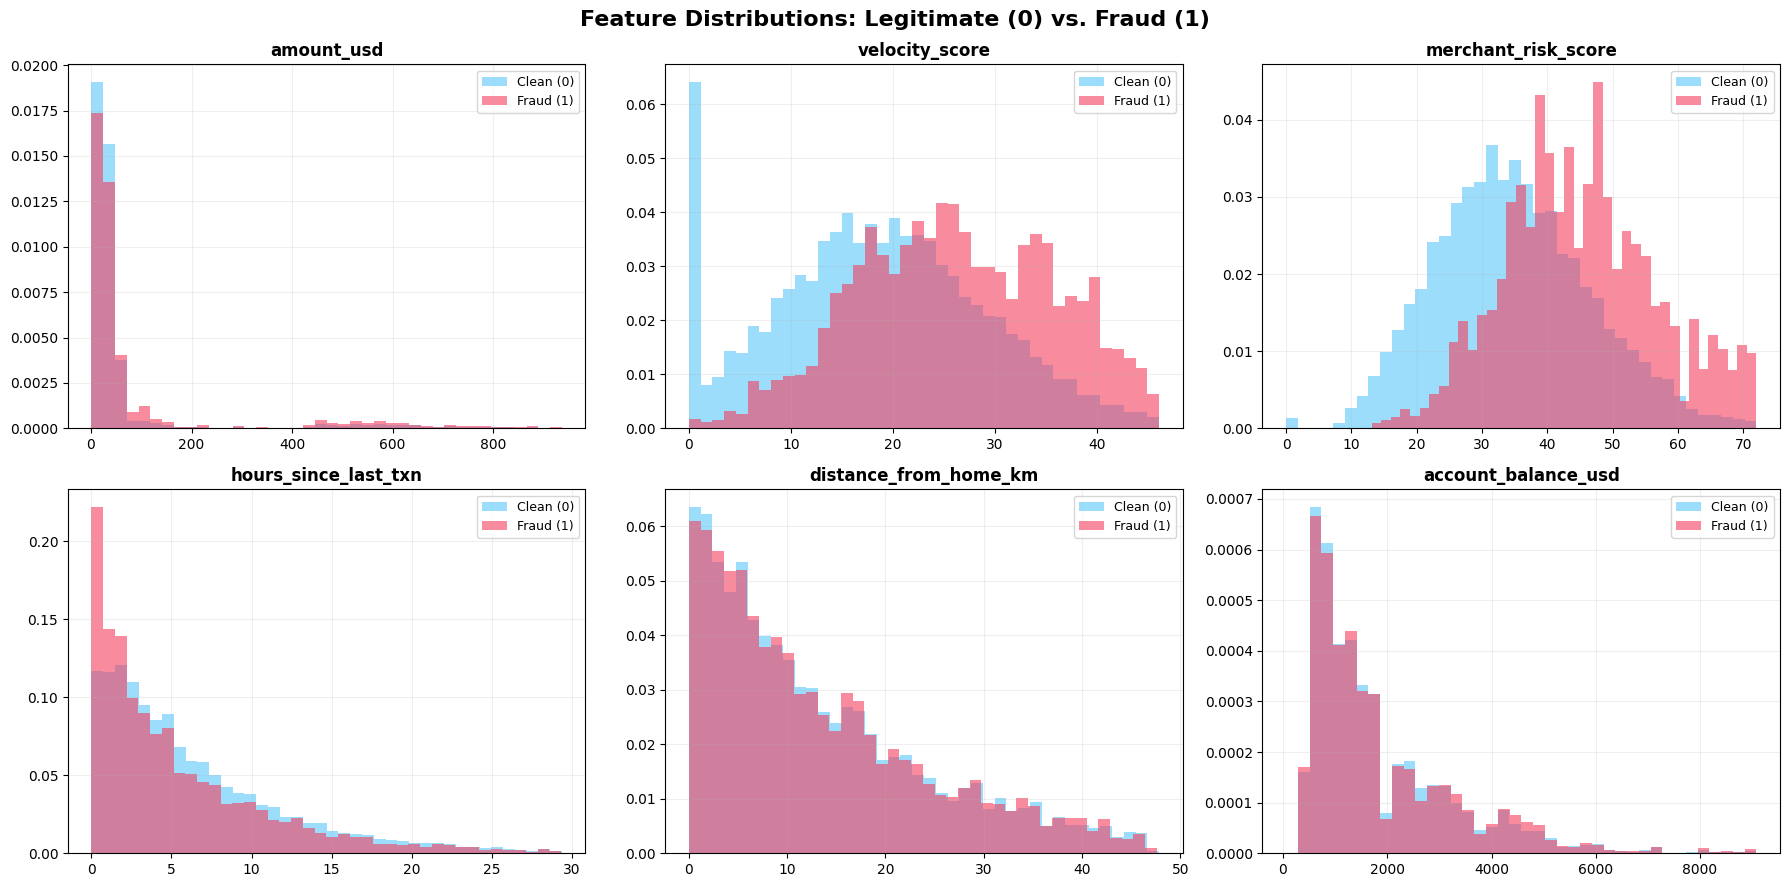

In [6]:
# ==============================================================================
# EDA — Numeric Feature Distributions by Fraud Class
# ==============================================================================
key_nums = [
    'amount_usd', 'velocity_score', 'merchant_risk_score',
    'hours_since_last_txn', 'distance_from_home_km', 'account_balance_usd'
]
plot_nums = [c for c in key_nums if c in train.columns]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
fig.suptitle('Feature Distributions: Legitimate (0) vs. Fraud (1)', fontsize=16, fontweight='bold')
axes_flat = axes.flatten()

for i, col in enumerate(plot_nums[:6]):
    ax = axes_flat[i]
    q_high = train[col].quantile(0.99)
    subset_0 = train[(train[TARGET] == 0) & (train[col] <= q_high)][col]
    subset_1 = train[(train[TARGET] == 1) & (train[col] <= q_high)][col]
    
    ax.hist(subset_0, bins=40, alpha=0.5, density=True, label='Clean (0)', color='#38bdf8')
    ax.hist(subset_1, bins=40, alpha=0.6, density=True, label='Fraud (1)', color='#f43f5e')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


<a id="fe"></a>
## 🛠️ 4. Feature Engineering — Risk Lift, Ratios & The String Trick


In [7]:
# ==============================================================================
# DOMAIN FEATURE ENGINEERING ENGINE
# ==============================================================================
def create_domain_features(df):
    """Generates financial risk metrics, transaction velocity ratios, and temporal interactions."""
    data = df.copy()
    
    # 1. Total Sparse Risk Indicator Flag Sum & Interactions
    flag_cols = [
        'is_foreign_transaction', 'is_new_merchant', 'used_vpn',
        'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt'
    ]
    present_flags = [c for c in flag_cols if c in data.columns]
    if len(present_flags) > 0:
        data['total_risk_flags'] = data[present_flags].sum(axis=1)
        data['has_any_risk_flag'] = (data['total_risk_flags'] > 0).astype(int)
        data['multiple_risk_flags'] = (data['total_risk_flags'] >= 2).astype(int)
    
    # 2. Financial & Velocity Ratios
    if 'amount_usd' in data.columns and 'account_balance_usd' in data.columns:
        data['amount_to_balance_ratio'] = data['amount_usd'] / (data['account_balance_usd'].clip(lower=0) + 1.0)
        data['amount_exceeds_balance'] = (data['amount_usd'] > data['account_balance_usd']).astype(int)
        
    if 'amount_usd' in data.columns and 'txn_count_last_24h' in data.columns:
        data['amount_per_recent_txn'] = data['amount_usd'] / (data['txn_count_last_24h'] + 1.0)
        data['hourly_txn_frequency'] = data['txn_count_last_24h'] / 24.0
        
    if 'amount_usd' in data.columns and 'hours_since_last_txn' in data.columns:
        data['amount_time_velocity'] = data['amount_usd'] / (data['hours_since_last_txn'] + 0.1)
        data['rapid_succession_flag'] = (data['hours_since_last_txn'] < 0.25).astype(int)
        
    if 'velocity_score' in data.columns and 'amount_usd' in data.columns:
        data['velocity_x_amount'] = data['velocity_score'] * np.log1p(data['amount_usd'])
        
    if 'merchant_risk_score' in data.columns and 'amount_usd' in data.columns:
        data['merchant_x_amount'] = data['merchant_risk_score'] * np.log1p(data['amount_usd'])
        
    if 'merchant_risk_score' in data.columns and 'velocity_score' in data.columns:
        data['composite_risk_score'] = data['merchant_risk_score'] * data['velocity_score']
        if 'total_risk_flags' in data.columns:
            data['amplified_risk_score'] = data['composite_risk_score'] * (1.0 + data['total_risk_flags'])
            
    if 'distance_from_home_km' in data.columns and 'customer_age' in data.columns:
        data['distance_per_age'] = data['distance_from_home_km'] / (data['customer_age'] + 1.0)
        data['extreme_distance_flag'] = (data['distance_from_home_km'] > 100.0).astype(int)
        
    if 'cvv_retry_count' in data.columns:
        data['cvv_retried_multiple'] = (data['cvv_retry_count'] >= 2).astype(int)
        
    if 'prior_disputes' in data.columns:
        data['has_prior_disputes'] = (data['prior_disputes'] > 0).astype(int)
        
    # 3. Cyclical Temporal Encodings
    if 'time_of_day_hour' in data.columns:
        data['hour_sin'] = np.sin(2 * np.pi * data['time_of_day_hour'] / 24.0)
        data['hour_cos'] = np.cos(2 * np.pi * data['time_of_day_hour'] / 24.0)
        data['is_night_txn'] = ((data['time_of_day_hour'] >= 23) | (data['time_of_day_hour'] <= 5)).astype(int)
        
    if 'day_of_week' in data.columns:
        data['is_weekend'] = (data['day_of_week'] >= 5).astype(int)
        
    # 4. Non-Linear Log Transforms for Heavy Tails
    for num_col in ['amount_usd', 'distance_from_home_km']:
        if num_col in data.columns:
            data[f'{num_col}_log'] = np.log1p(data[num_col].clip(lower=0))
            
    return data

train_fe = create_domain_features(train)
test_fe  = create_domain_features(test)

print(f'Features after domain engineering: {train_fe.shape[1]} (from {train.shape[1]})')


Features after domain engineering: 49 (from 26)


In [8]:
# ==============================================================================
# OUT-OF-FOLD (OOF) TARGET ENCODING & THE SYNTHETIC STRING TRICK
# ==============================================================================
# Identify Categoricals & Discrete Numerics
raw_cats = [c for c in train_fe.select_dtypes(include=['object', 'category', 'bool']).columns if c not in [ID_COL, TARGET]]
discrete_nums = [c for c in ['cvv_retry_count', 'prior_disputes', 'day_of_week'] if c in train_fe.columns]

# Apply String Trick: converting discrete numbers to string categories
for col in discrete_nums:
    train_fe[f'{col}_str'] = train_fe[col].astype(str)
    test_fe[f'{col}_str']  = test_fe[col].astype(str)

encode_cols = raw_cats + [f'{c}_str' for c in discrete_nums]
print(f'Columns selected for Target Encoding ({len(encode_cols)}): {encode_cols}')

def target_encode_oof(train_df, test_df, cols, target, n_folds=5, seed=42, smoothing=20.0):
    """Computes leak-free smoothed out-of-fold target encodings."""
    tr = train_df.copy()
    te = test_df.copy()
    global_mean = tr[target].mean()
    
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    
    for col in cols:
        te_col = f'{col}_te'
        tr[te_col] = global_mean
        
        # OOF calculation for training set
        for tr_idx, val_idx in skf.split(tr, tr[target]):
            fold_tr = tr.iloc[tr_idx]
            counts = fold_tr.groupby(col)[target].count()
            means = fold_tr.groupby(col)[target].mean()
            # Empirical Bayes / Laplace smoothing formula
            smoothed = (counts * means + smoothing * global_mean) / (counts + smoothing)
            tr.loc[tr.index[val_idx], te_col] = tr.iloc[val_idx][col].map(smoothed).fillna(global_mean).values
            
        # Full training set mapping for test set
        full_counts = tr.groupby(col)[target].count()
        full_means = tr.groupby(col)[target].mean()
        full_smoothed = (full_counts * full_means + smoothing * global_mean) / (full_counts + smoothing)
        te[te_col] = te[col].map(full_smoothed).fillna(global_mean)
        
    return tr, te

train_fe, test_fe = target_encode_oof(train_fe, test_fe, encode_cols, TARGET, CFG.N_FOLDS, CFG.SEED, CFG.SMOOTHING)

# Label encode original categoricals for native tree compatibility
for col in raw_cats:
    le = LabelEncoder()
    combined = pd.concat([train_fe[col].astype(str), test_fe[col].astype(str)])
    le.fit(combined)
    train_fe[col] = le.transform(train_fe[col].astype(str))
    test_fe[col]  = le.transform(test_fe[col].astype(str))

# Drop intermediate string columns
str_cols = [f'{c}_str' for c in discrete_nums]
train_fe.drop(columns=str_cols, inplace=True)
test_fe.drop(columns=str_cols, inplace=True)

print(f'✅ Out-of-fold target encoding complete! Added {len(encode_cols)} smoothed target features.')


Columns selected for Target Encoding (14): ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt', 'cvv_retry_count_str', 'prior_disputes_str', 'day_of_week_str']
✅ Out-of-fold target encoding complete! Added 14 smoothed target features.


In [9]:
# ==============================================================================
# FEATURE MATRIX PREPARATION
# ==============================================================================
exclude_features = [ID_COL, TARGET]
FEATURES = [c for c in train_fe.columns if c not in exclude_features]

X = train_fe[FEATURES].copy().replace([np.inf, -np.inf], np.nan)
y = train_fe[TARGET].values
X_test = test_fe[FEATURES].copy().replace([np.inf, -np.inf], np.nan)

print(f'Total Modeling Features: {len(FEATURES)}')
print(f'X shape: {X.shape} | y shape: {y.shape} | X_test shape: {X_test.shape}')


Total Modeling Features: 61
X shape: (699960, 61) | y shape: (699960,) | X_test shape: (299984, 61)


<a id="optuna"></a>
## 🔍 5. Optuna Hyperparameter Optimization


In [10]:
# ==============================================================================
# OPTUNA — LightGBM Hyperparameter Tuning (Stratified 3-Fold CV)
# ==============================================================================
def objective_lgb(trial):
    params = {
        'n_estimators': 3000,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.08, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 31, 127),
        'max_depth': trial.suggest_int('max_depth', 5, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 0.95),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 0.95),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 5.0),
        'random_state': CFG.SEED,
        'verbosity': -1,
        'n_jobs': -1
    }
    
    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=CFG.SEED)
    scores = []
    
    for tr_idx, val_idx in skf.split(X, y):
        model = lgb.LGBMClassifier(**params)
        model.fit(
            X.iloc[tr_idx], y[tr_idx],
            eval_set=[(X.iloc[val_idx], y[val_idx])],
            callbacks=[lgb.early_stopping(100, verbose=False)]
        )
        preds = model.predict_proba(X.iloc[val_idx])[:, 1]
        scores.append(roc_auc_score(y[val_idx], preds))
        
    return np.mean(scores)

print('🔍 Tuning LightGBM via Optuna...')
study_lgb = optuna.create_study(direction='maximize', sampler=TPESampler(seed=CFG.SEED))
study_lgb.optimize(objective_lgb, n_trials=CFG.OPTUNA_TRIALS, timeout=CFG.OPTUNA_TIMEOUT)
best_lgb_params = study_lgb.best_params
print(f'✅ Best LightGBM ROC-AUC: {study_lgb.best_value:.5f}')


🔍 Tuning LightGBM via Optuna...
✅ Best LightGBM ROC-AUC: 0.94288


In [11]:
# ==============================================================================
# OPTUNA — XGBoost Hyperparameter Tuning (Stratified 3-Fold CV)
# ==============================================================================
def objective_xgb(trial):
    params = {
        'n_estimators': 3000,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.08, log=True),
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 20),
        'subsample': trial.suggest_float('subsample', 0.6, 0.95),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 0.95),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 5.0),
        'tree_method': 'hist',
        'device': 'cuda' if CFG.USE_GPU else 'cpu',
        'random_state': CFG.SEED,
        'n_jobs': -1,
        'early_stopping_rounds': 100,
        'eval_metric': 'auc'
    }
    
    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=CFG.SEED)
    scores = []
    
    for tr_idx, val_idx in skf.split(X, y):
        model = xgb.XGBClassifier(**params)
        model.fit(
            X.iloc[tr_idx], y[tr_idx],
            eval_set=[(X.iloc[val_idx], y[val_idx])],
            verbose=False
        )
        preds = model.predict_proba(X.iloc[val_idx])[:, 1]
        scores.append(roc_auc_score(y[val_idx], preds))
        
    return np.mean(scores)

print('🔍 Tuning XGBoost via Optuna...')
study_xgb = optuna.create_study(direction='maximize', sampler=TPESampler(seed=CFG.SEED))
study_xgb.optimize(objective_xgb, n_trials=CFG.OPTUNA_TRIALS, timeout=CFG.OPTUNA_TIMEOUT)
best_xgb_params = study_xgb.best_params
print(f'✅ Best XGBoost ROC-AUC: {study_xgb.best_value:.5f}')


🔍 Tuning XGBoost via Optuna...
✅ Best XGBoost ROC-AUC: 0.94400


In [12]:
# ==============================================================================
# OPTUNA — CatBoost Hyperparameter Tuning (Stratified 3-Fold CV)
# ==============================================================================
def objective_cat(trial):
    params = {
        'iterations': 3000,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.08, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 15.0, log=True),
        'random_strength': trial.suggest_float('random_strength', 1e-2, 5.0),
        'auto_class_weights': 'Balanced' if trial.suggest_categorical('balanced', [True, False]) else None,
        'random_seed': CFG.SEED,
        'task_type': 'GPU' if CFG.USE_GPU else 'CPU',
        'verbose': 0,
        'early_stopping_rounds': 100,
        'eval_metric': 'AUC'
    }
    
    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=CFG.SEED)
    scores = []
    
    for tr_idx, val_idx in skf.split(X, y):
        model = CatBoostClassifier(**params)
        model.fit(
            X.iloc[tr_idx], y[tr_idx],
            eval_set=(X.iloc[val_idx], y[val_idx])
        )
        preds = model.predict_proba(X.iloc[val_idx])[:, 1]
        scores.append(roc_auc_score(y[val_idx], preds))
        
    return np.mean(scores)

print('🔍 Tuning CatBoost via Optuna...')
study_cat = optuna.create_study(direction='maximize', sampler=TPESampler(seed=CFG.SEED))
study_cat.optimize(objective_cat, n_trials=CFG.OPTUNA_TRIALS, timeout=CFG.OPTUNA_TIMEOUT)
best_cat_params = study_cat.best_params
print(f'✅ Best CatBoost ROC-AUC: {study_cat.best_value:.5f}')


🔍 Tuning CatBoost via Optuna...


Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric perio

✅ Best CatBoost ROC-AUC: 0.94458


<a id="training"></a>
## 🤖 6. Multi-Model 5-Fold Stratified CV Training


In [13]:
# ==============================================================================
# HONEST 5-FOLD CROSS-VALIDATION ENGINE
# ==============================================================================
def train_model_cv(model_name, X_tr, y_tr, X_te, n_splits, seed, best_params):
    """Executes full 5-fold CV while monitoring generalization gaps per fold."""
    oof_preds = np.zeros(len(X_tr))
    test_preds = np.zeros(len(X_te))
    fold_train_scores = []
    fold_val_scores = []
    trees_used = []
    
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    print(f'\n{"="*65}')
    print(f'Training {model_name} ({n_splits}-Fold Stratified CV with Optuna Params)')
    print(f'{"="*65}')
    
    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_tr, y_tr)):
        Xf_tr, Xf_val = X_tr.iloc[tr_idx], X_tr.iloc[val_idx]
        yf_tr, yf_val = y_tr[tr_idx], y_tr[val_idx]
        
        if model_name == 'LightGBM':
            model = lgb.LGBMClassifier(
                n_estimators=6000,
                learning_rate=best_params.get('learning_rate', 0.03),
                num_leaves=best_params.get('num_leaves', 63),
                max_depth=best_params.get('max_depth', 8),
                min_child_samples=best_params.get('min_child_samples', 40),
                subsample=best_params.get('subsample', 0.8),
                colsample_bytree=best_params.get('colsample_bytree', 0.8),
                reg_alpha=best_params.get('reg_alpha', 0.1),
                reg_lambda=best_params.get('reg_lambda', 1.0),
                scale_pos_weight=best_params.get('scale_pos_weight', 1.0),
                random_state=seed + fold,
                verbosity=-1, n_jobs=-1
            )
            model.fit(
                Xf_tr, yf_tr, eval_set=[(Xf_val, yf_val)],
                callbacks=[lgb.early_stopping(CFG.EARLY_STOPPING, verbose=False)]
            )
            trees = model.best_iteration_
            
        elif model_name == 'XGBoost':
            model = xgb.XGBClassifier(
                n_estimators=6000,
                learning_rate=best_params.get('learning_rate', 0.03),
                max_depth=best_params.get('max_depth', 6),
                min_child_weight=best_params.get('min_child_weight', 5),
                subsample=best_params.get('subsample', 0.8),
                colsample_bytree=best_params.get('colsample_bytree', 0.8),
                reg_alpha=best_params.get('reg_alpha', 0.1),
                reg_lambda=best_params.get('reg_lambda', 1.0),
                scale_pos_weight=best_params.get('scale_pos_weight', 1.0),
                tree_method='hist',
                device='cuda' if CFG.USE_GPU else 'cpu',
                random_state=seed + fold,
                n_jobs=-1,
                early_stopping_rounds=CFG.EARLY_STOPPING,
                eval_metric='auc'
            )
            model.fit(Xf_tr, yf_tr, eval_set=[(Xf_val, yf_val)], verbose=False)
            trees = model.best_iteration
            
        elif model_name == 'CatBoost':
            model = CatBoostClassifier(
                iterations=6000,
                learning_rate=best_params.get('learning_rate', 0.03),
                depth=best_params.get('depth', 6),
                l2_leaf_reg=best_params.get('l2_leaf_reg', 5.0),
                random_strength=best_params.get('random_strength', 1.0),
                auto_class_weights='Balanced' if best_params.get('balanced', False) else None,
                random_seed=seed + fold,
                task_type='GPU' if CFG.USE_GPU else 'CPU',
                verbose=0,
                early_stopping_rounds=CFG.EARLY_STOPPING,
                eval_metric='AUC'
            )
            model.fit(Xf_tr, yf_tr, eval_set=(Xf_val, yf_val))
            trees = model.best_iteration_
            
        # Predictions
        oof_preds[val_idx] = model.predict_proba(Xf_val)[:, 1]
        tr_pred = model.predict_proba(Xf_tr)[:, 1]
        test_preds += model.predict_proba(X_te)[:, 1] / n_splits
        
        train_auc = roc_auc_score(yf_tr, tr_pred)
        val_auc = roc_auc_score(yf_val, oof_preds[val_idx])
        fold_train_scores.append(train_auc)
        fold_val_scores.append(val_auc)
        trees_used.append(trees)
        
        gap = train_auc - val_auc
        status = '✅ Good' if gap < 0.015 else ('⚠️ Mild Gap' if gap < 0.035 else '🔴 Overfit')
        print(f'  Fold {fold+1} | Train AUC: {train_auc:.5f} | Val AUC: {val_auc:.5f} | Gap: {gap:.5f} {status} | Trees: {trees}')
        
    overall_auc = roc_auc_score(y_tr, oof_preds)
    avg_gap = np.mean(fold_train_scores) - np.mean(fold_val_scores)
    std_val = np.std(fold_val_scores)
    
    print(f'\n  📊 Overall OOF ROC-AUC : {overall_auc:.5f}')
    print(f'  📊 Mean Train ROC-AUC  : {np.mean(fold_train_scores):.5f}')
    print(f'  📊 Fold Stability (std): {std_val:.5f}')
    print(f'  📊 Avg Generalization Gap: {avg_gap:.5f}')
    
    diagnostics = {
        'train_scores': fold_train_scores,
        'val_scores': fold_val_scores,
        'avg_gap': avg_gap,
        'std_val': std_val,
        'trees': trees_used
    }
    return oof_preds, test_preds, overall_auc, diagnostics


In [14]:
# Train LightGBM
lgb_oof, lgb_test, lgb_auc, lgb_diag = train_model_cv(
    'LightGBM', X, y, X_test, CFG.N_FOLDS, CFG.SEED, best_lgb_params
)



Training LightGBM (5-Fold Stratified CV with Optuna Params)
  Fold 1 | Train AUC: 0.99348 | Val AUC: 0.94157 | Gap: 0.05191 🔴 Overfit | Trees: 1847
  Fold 2 | Train AUC: 0.99460 | Val AUC: 0.94493 | Gap: 0.04967 🔴 Overfit | Trees: 2041
  Fold 3 | Train AUC: 0.99418 | Val AUC: 0.94790 | Gap: 0.04627 🔴 Overfit | Trees: 1921
  Fold 4 | Train AUC: 0.99355 | Val AUC: 0.94393 | Gap: 0.04962 🔴 Overfit | Trees: 1777
  Fold 5 | Train AUC: 0.99513 | Val AUC: 0.93915 | Gap: 0.05598 🔴 Overfit | Trees: 2004

  📊 Overall OOF ROC-AUC : 0.94345
  📊 Mean Train ROC-AUC  : 0.99419
  📊 Fold Stability (std): 0.00298
  📊 Avg Generalization Gap: 0.05069


In [15]:
# Train XGBoost
xgb_oof, xgb_test, xgb_auc, xgb_diag = train_model_cv(
    'XGBoost', X, y, X_test, CFG.N_FOLDS, CFG.SEED + 10, best_xgb_params
)



Training XGBoost (5-Fold Stratified CV with Optuna Params)
  Fold 1 | Train AUC: 0.95884 | Val AUC: 0.94532 | Gap: 0.01352 ✅ Good | Trees: 2167
  Fold 2 | Train AUC: 0.96201 | Val AUC: 0.94478 | Gap: 0.01723 ⚠️ Mild Gap | Trees: 2712
  Fold 3 | Train AUC: 0.95760 | Val AUC: 0.94894 | Gap: 0.00866 ✅ Good | Trees: 2033
  Fold 4 | Train AUC: 0.95980 | Val AUC: 0.94737 | Gap: 0.01243 ✅ Good | Trees: 2319
  Fold 5 | Train AUC: 0.96253 | Val AUC: 0.94648 | Gap: 0.01605 ⚠️ Mild Gap | Trees: 2869

  📊 Overall OOF ROC-AUC : 0.94655
  📊 Mean Train ROC-AUC  : 0.96015
  📊 Fold Stability (std): 0.00149
  📊 Avg Generalization Gap: 0.01358


In [16]:
# Train CatBoost
cat_oof, cat_test, cat_auc, cat_diag = train_model_cv(
    'CatBoost', X, y, X_test, CFG.N_FOLDS, CFG.SEED + 20, best_cat_params
)



Training CatBoost (5-Fold Stratified CV with Optuna Params)


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 1 | Train AUC: 0.95327 | Val AUC: 0.94752 | Gap: 0.00576 ✅ Good | Trees: 720


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 2 | Train AUC: 0.95668 | Val AUC: 0.94310 | Gap: 0.01358 ✅ Good | Trees: 941


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 3 | Train AUC: 0.95423 | Val AUC: 0.94292 | Gap: 0.01130 ✅ Good | Trees: 728


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 4 | Train AUC: 0.95486 | Val AUC: 0.94546 | Gap: 0.00940 ✅ Good | Trees: 820


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 5 | Train AUC: 0.95213 | Val AUC: 0.94631 | Gap: 0.00582 ✅ Good | Trees: 581

  📊 Overall OOF ROC-AUC : 0.94503
  📊 Mean Train ROC-AUC  : 0.95423
  📊 Fold Stability (std): 0.00180
  📊 Avg Generalization Gap: 0.00917


<a id="stacking"></a>
## 🔮 7. Meta-Stacking Ensemble & Rank Blending


In [17]:
# ==============================================================================
# META-STACKING & LOGIT-RANK BLENDING
# ==============================================================================
print('\n' + '='*65)
print('Constructing Meta-Stacking & Rank-Space Ensembles')
print('='*65)

# Stacking Base OOF and Test Matrices
stack_train = np.column_stack([lgb_oof, xgb_oof, cat_oof])
stack_test  = np.column_stack([lgb_test, xgb_test, cat_test])

# Polynomial Interaction Terms
stack_train_poly = np.column_stack([
    stack_train,
    lgb_oof * xgb_oof,
    lgb_oof * cat_oof,
    xgb_oof * cat_oof,
    np.mean(stack_train, axis=1)
])
stack_test_poly = np.column_stack([
    stack_test,
    lgb_test * xgb_test,
    lgb_test * cat_test,
    xgb_test * cat_test,
    np.mean(stack_test, axis=1)
])

# Meta-Learner: Regularized Logistic Regression
meta_oof = np.zeros(len(stack_train_poly))
meta_test_preds = np.zeros(len(stack_test_poly))

skf_meta = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
for tr_idx, val_idx in skf_meta.split(stack_train_poly, y):
    lr = LogisticRegression(C=0.5, max_iter=1000, random_state=CFG.SEED)
    lr.fit(stack_train_poly[tr_idx], y[tr_idx])
    meta_oof[val_idx] = lr.predict_proba(stack_train_poly[val_idx])[:, 1]
    meta_test_preds += lr.predict_proba(stack_test_poly)[:, 1] / CFG.N_FOLDS

meta_auc = roc_auc_score(y, meta_oof)
print(f'  📊 Meta-Learner (Logistic Regression) OOF ROC-AUC: {meta_auc:.5f}')

# Strategy 2: Inverse-Variance / Weighted Probability Average
weights = np.array([lgb_auc, xgb_auc, cat_auc]) ** 4  # Exponential weight favoring best
weights = weights / weights.sum()
print(f'  Ensemble Weights -> LightGBM: {weights[0]:.3f} | XGBoost: {weights[1]:.3f} | CatBoost: {weights[2]:.3f}')

weighted_oof = weights[0]*lgb_oof + weights[1]*xgb_oof + weights[2]*cat_oof
weighted_test = weights[0]*lgb_test + weights[1]*xgb_test + weights[2]*cat_test
weighted_auc = roc_auc_score(y, weighted_oof)
print(f'  📊 Weighted Probability Average OOF ROC-AUC: {weighted_auc:.5f}')

# Strategy 3: Rank-Space Percentile Average
from scipy.stats import rankdata
rank_oof = (
    weights[0] * (rankdata(lgb_oof) / len(lgb_oof)) +
    weights[1] * (rankdata(xgb_oof) / len(xgb_oof)) +
    weights[2] * (rankdata(cat_oof) / len(cat_oof))
)
rank_test = (
    weights[0] * (rankdata(lgb_test) / len(lgb_test)) +
    weights[1] * (rankdata(xgb_test) / len(xgb_test)) +
    weights[2] * (rankdata(cat_test) / len(cat_test))
)
rank_auc = roc_auc_score(y, rank_oof)
print(f'  📊 Rank-Space Percentile Average OOF ROC-AUC: {rank_auc:.5f}')

# Select Champion Ensemble Strategy
best_score = max(meta_auc, weighted_auc, rank_auc)
if best_score == meta_auc:
    final_oof = meta_oof
    final_test = meta_test_preds
    champion_name = 'Meta-Stacking (LogisticRegression)'
elif best_score == weighted_auc:
    final_oof = weighted_oof
    final_test = weighted_test
    champion_name = 'Weighted Probability Average'
else:
    final_oof = rank_oof
    final_test = rank_test
    champion_name = 'Rank-Space Percentile Average'

print(f'\n  🏆 CHAMPION ENSEMBLE: {champion_name} (OOF AUC: {best_score:.5f})')



Constructing Meta-Stacking & Rank-Space Ensembles
  📊 Meta-Learner (Logistic Regression) OOF ROC-AUC: 0.94555
  Ensemble Weights -> LightGBM: 0.331 | XGBoost: 0.336 | CatBoost: 0.333
  📊 Weighted Probability Average OOF ROC-AUC: 0.94587
  📊 Rank-Space Percentile Average OOF ROC-AUC: 0.94633

  🏆 CHAMPION ENSEMBLE: Rank-Space Percentile Average (OOF AUC: 0.94633)


<a id="diagnostics"></a>
## 🩺 8. Generalization Diagnostics (Overfit / Underfit Scorecard)


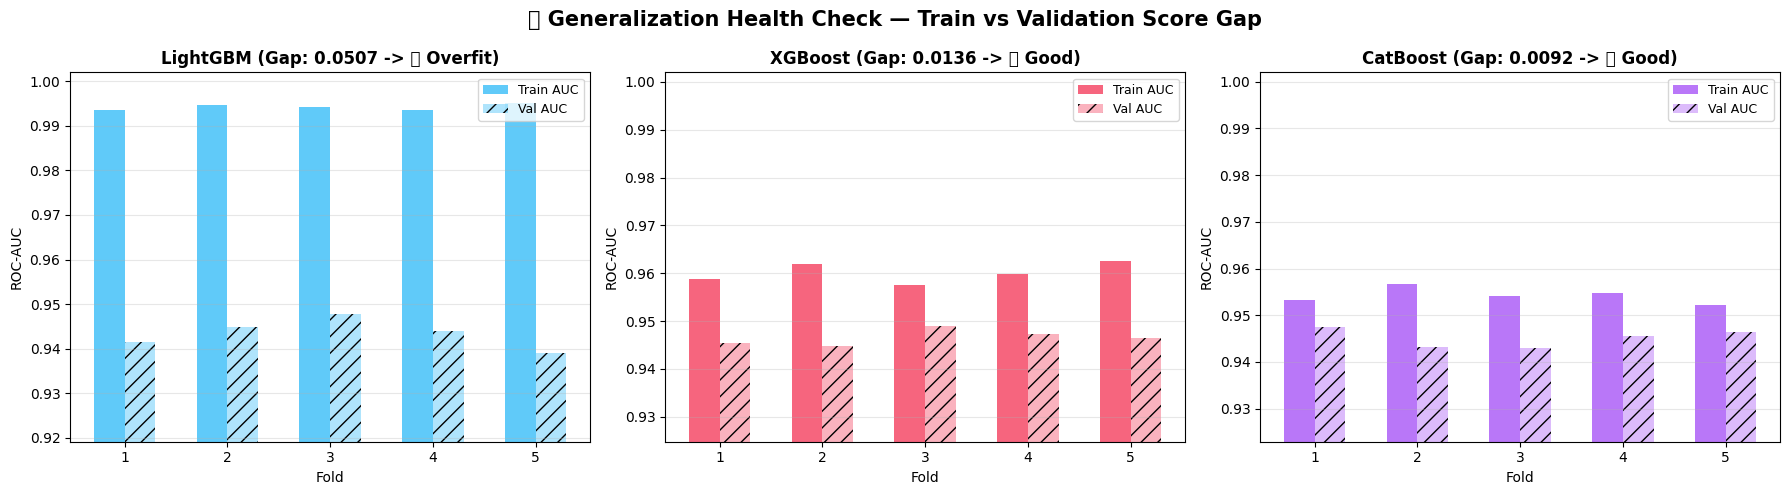

In [18]:
# ==============================================================================
# DIAGNOSTICS PANEL 1: Train vs. Validation Gap Analysis
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('🩺 Generalization Health Check — Train vs Validation Score Gap', fontsize=15, fontweight='bold')

models_diag = [('LightGBM', lgb_diag, '#38bdf8'), ('XGBoost', xgb_diag, '#f43f5e'), ('CatBoost', cat_diag, '#a855f7')]

for ax, (name, diag, color) in zip(axes, models_diag):
    folds = range(1, len(diag['train_scores']) + 1)
    ax.bar([f - 0.15 for f in folds], diag['train_scores'], 0.3, label='Train AUC', color=color, alpha=0.8)
    ax.bar([f + 0.15 for f in folds], diag['val_scores'], 0.3, label='Val AUC', color=color, alpha=0.4, hatch='//')
    
    gap = diag['avg_gap']
    verdict = '✅ Good' if gap < 0.015 else ('⚠️ Mild' if gap < 0.035 else '🔴 Overfit')
    ax.set_title(f'{name} (Gap: {gap:.4f} -> {verdict})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Fold')
    ax.set_ylabel('ROC-AUC')
    ax.set_ylim(min(diag['val_scores']) - 0.02, 1.002)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


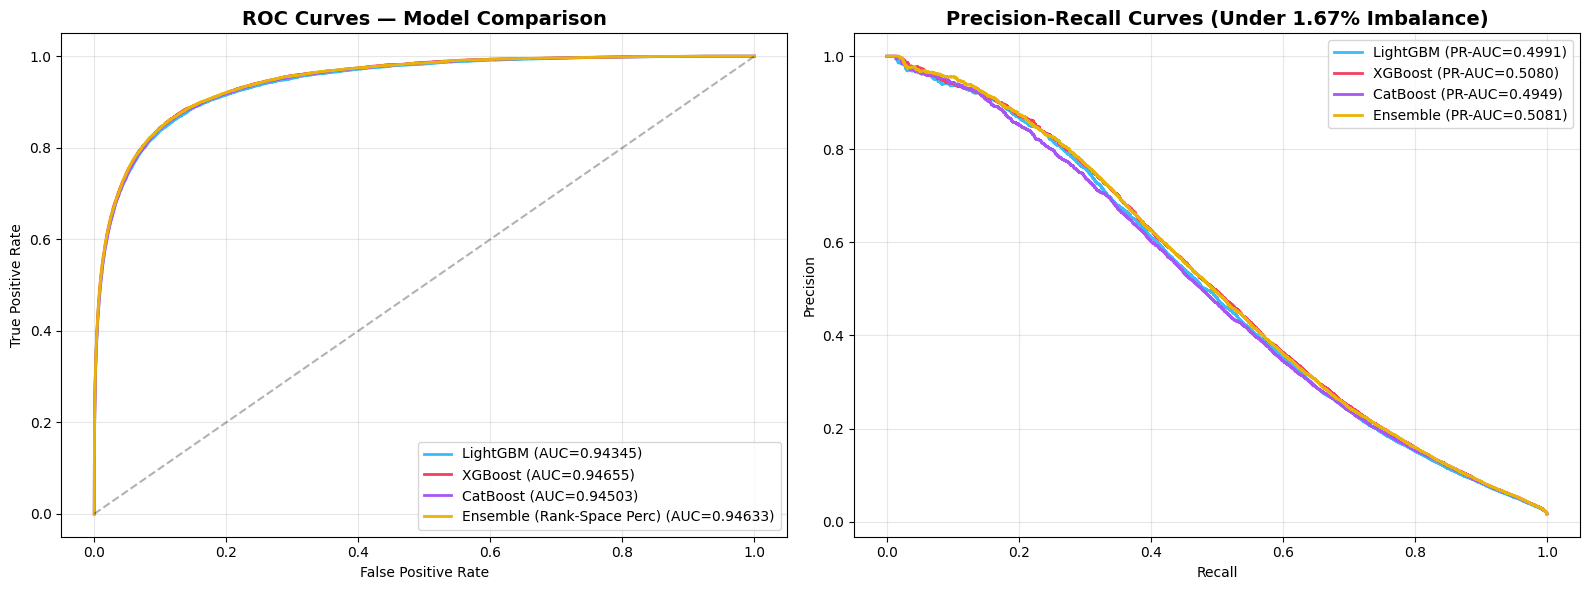

In [19]:
# ==============================================================================
# DIAGNOSTICS PANEL 2: ROC & Precision-Recall Curves
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ROC Curves
ax = axes[0]
for name, preds, score, col in [
    ('LightGBM', lgb_oof, lgb_auc, '#38bdf8'),
    ('XGBoost', xgb_oof, xgb_auc, '#f43f5e'),
    ('CatBoost', cat_oof, cat_auc, '#a855f7'),
    (f'Ensemble ({champion_name[:15]})', final_oof, best_score, '#eab308')
]:
    fpr, tpr, _ = roc_curve(y, preds)
    ax.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={score:.5f})', color=col)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax.set_title('ROC Curves — Model Comparison', fontsize=14, fontweight='bold')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# Precision-Recall Curves
ax = axes[1]
for name, preds, col in [
    ('LightGBM', lgb_oof, '#38bdf8'),
    ('XGBoost', xgb_oof, '#f43f5e'),
    ('CatBoost', cat_oof, '#a855f7'),
    ('Ensemble', final_oof, '#eab308')
]:
    prec, rec, _ = precision_recall_curve(y, preds)
    ap = average_precision_score(y, preds)
    ax.plot(rec, prec, linewidth=2, label=f'{name} (PR-AUC={ap:.4f})', color=col)

ax.set_title('Precision-Recall Curves (Under 1.67% Imbalance)', fontsize=14, fontweight='bold')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


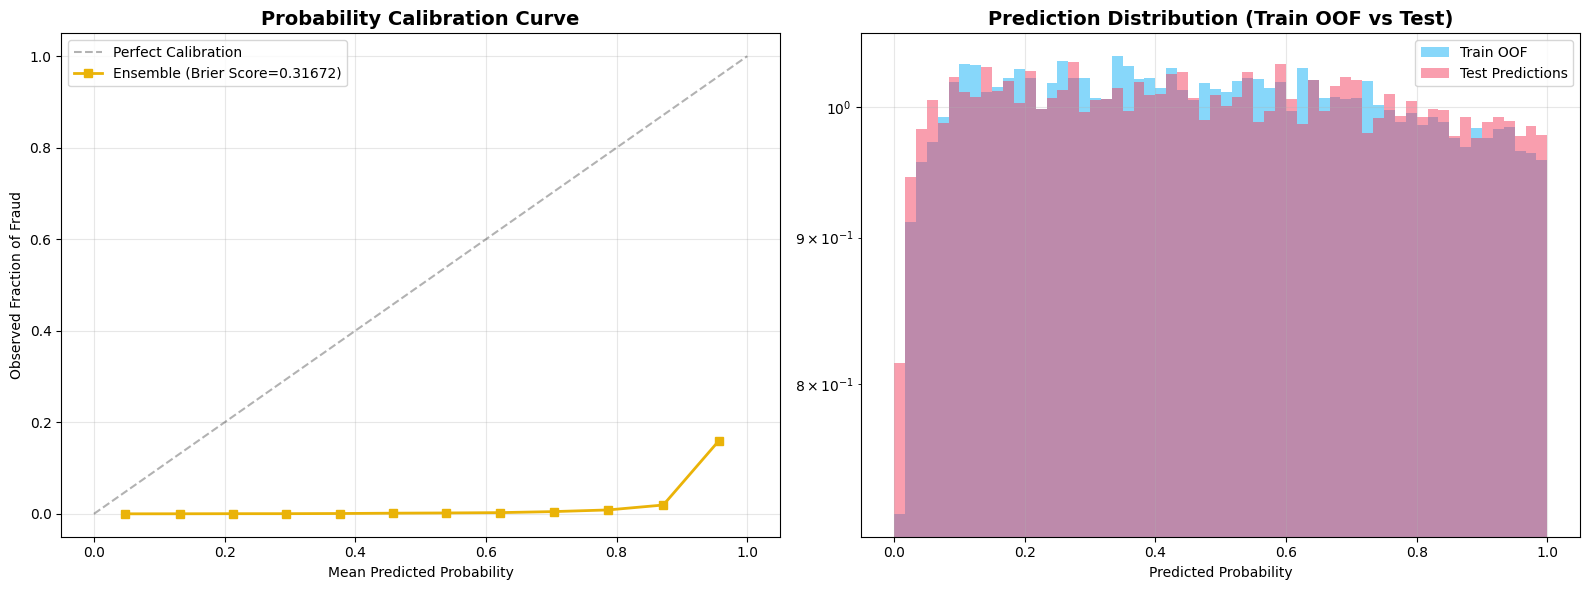

In [20]:
# ==============================================================================
# DIAGNOSTICS PANEL 3: Calibration & Distribution Drift (Train OOF vs Test)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Calibration Curve
ax = axes[0]
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Perfect Calibration')
frac_pos, mean_pred = calibration_curve(y, final_oof, n_bins=12, strategy='quantile')
brier = brier_score_loss(y, final_oof)
ax.plot(mean_pred, frac_pos, 's-', color='#eab308', linewidth=2, label=f'Ensemble (Brier Score={brier:.5f})')
ax.set_title('Probability Calibration Curve', fontsize=14, fontweight='bold')
ax.set_xlabel('Mean Predicted Probability')
ax.set_ylabel('Observed Fraction of Fraud')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# Distribution Shift (OOF vs Test)
ax = axes[1]
ax.hist(final_oof, bins=60, alpha=0.6, density=True, color='#38bdf8', label='Train OOF')
ax.hist(final_test, bins=60, alpha=0.5, density=True, color='#f43f5e', label='Test Predictions')
ax.set_title('Prediction Distribution (Train OOF vs Test)', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted Probability')
ax.set_yscale('log')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [21]:
# ==============================================================================
# 🩺 GENERALIZATION SCORECARD
# ==============================================================================
print('\n' + '='*70)
print('🩺 AUTOMATED GENERALIZATION SCORECARD — Overfit / Underfit Audit')
print('='*70)

checks = []

# Check 1: Train vs Val AUC Gap
for name, diag in [('LightGBM', lgb_diag), ('XGBoost', xgb_diag), ('CatBoost', cat_diag)]:
    gap = diag['avg_gap']
    if gap < 0.015:
        status = '✅ EXCELLENT'
        checks.append(1.0)
    elif gap < 0.035:
        status = '⚠️  MILD GAP'
        checks.append(0.6)
    else:
        status = '🔴 OVERFIT'
        checks.append(0.0)
    print(f'  [{status}] {name} Train-Val Gap: {gap:.5f}')

# Check 2: Fold Score Stability (CV consistency)
for name, diag in [('LightGBM', lgb_diag), ('XGBoost', xgb_diag), ('CatBoost', cat_diag)]:
    std = diag['std_val']
    if std < 0.003:
        status = '✅ STABLE'
        checks.append(1.0)
    elif std < 0.006:
        status = '⚠️  MODERATE'
        checks.append(0.5)
    else:
        status = '🔴 UNSTABLE'
        checks.append(0.0)
    print(f'  [{status}] {name} Fold Stability (std): {std:.5f}')

# Check 3: Kolmogorov-Smirnov Test (Covariate Shift)
ks_stat, ks_pval = ks_2samp(final_oof, final_test)
if ks_stat < 0.025:
    status = '✅ ALIGNED'
    checks.append(1.0)
elif ks_stat < 0.05:
    status = '⚠️  MINOR SHIFT'
    checks.append(0.6)
else:
    status = '🔴 DRIFT DETECTED'
    checks.append(0.0)
print(f'  [{status}] OOF vs Test Distribution KS Stat: {ks_stat:.5f} (p={ks_pval:.4f})')

# Check 4: Ensemble Improvement Lift
best_single = max(lgb_auc, xgb_auc, cat_auc)
lift = best_score - best_single
if lift > 0.001:
    status = '✅ DIVERSE BOOST'
    checks.append(1.0)
elif lift >= 0.0:
    status = '✅ POSITIVE'
    checks.append(0.8)
else:
    status = '🔴 ENSEMBLE DEGRADATION'
    checks.append(0.0)
print(f'  [{status}] Ensemble Lift: {lift:+.5f} (Best Single: {best_single:.5f})')

# Final Verdict
score = np.mean(checks)
print(f'\n  {"="*50}')
if score >= 0.85:
    verdict = '✅ MODEL IS EXCELLENTLY GENERALIZED — Ready for Submission!'
elif score >= 0.65:
    verdict = '⚠️  MINOR GENERALIZATION CONCERNS — Safe to submit, monitor LB.'
else:
    verdict = '🔴 POTENTIAL OVERFITTING DETECTED — Regularization recommended.'

print(f'  GENERALIZATION HEALTH SCORE: {score:.2f} / 1.00')
print(f'  VERDICT: {verdict}')
print(f'  {"="*50}')



🩺 AUTOMATED GENERALIZATION SCORECARD — Overfit / Underfit Audit
  [🔴 OVERFIT] LightGBM Train-Val Gap: 0.05069
  [✅ EXCELLENT] XGBoost Train-Val Gap: 0.01358
  [✅ EXCELLENT] CatBoost Train-Val Gap: 0.00917
  [✅ STABLE] LightGBM Fold Stability (std): 0.00298
  [✅ STABLE] XGBoost Fold Stability (std): 0.00149
  [✅ STABLE] CatBoost Fold Stability (std): 0.00180
  [✅ ALIGNED] OOF vs Test Distribution KS Stat: 0.00353 (p=0.0108)
  [🔴 ENSEMBLE DEGRADATION] Ensemble Lift: -0.00021 (Best Single: 0.94655)

  GENERALIZATION HEALTH SCORE: 0.75 / 1.00
  VERDICT: ⚠️  MINOR GENERALIZATION CONCERNS — Safe to submit, monitor LB.


<a id="submission"></a>
## 📤 9. Submission & Verification


In [22]:
# ==============================================================================
# VERIFIED SUBMISSION PIPELINE
# ==============================================================================
submission = sample_sub[[ID_COL]].copy() if sample_sub is not None else pd.DataFrame({ID_COL: test[ID_COL]})
submission[TARGET] = np.clip(final_test, 0.0, 1.0)

print('Submission Preview:')
display(submission.head(10))

print(f'\nSubmission Shape : {submission.shape}')
print(f'Predicted Range  : [{submission[TARGET].min():.6f}, {submission[TARGET].max():.6f}]')
print(f'Mean Fraud Prob  : {submission[TARGET].mean():.6f} (Train Rate: {train[TARGET].mean():.6f})')
print(f'Null Predictions : {submission[TARGET].isnull().sum()}')

# Sanity Assertions
if sample_sub is not None:
    assert len(submission) == len(sample_sub), f'Row count mismatch! {len(submission)} vs {len(sample_sub)}'
    assert list(submission.columns) == list(sample_sub.columns), f'Column mismatch! {list(submission.columns)} vs {list(sample_sub.columns)}'
    print('✅ Shape and columns match sample_submission.csv perfectly!')

assert submission[ID_COL].isnull().sum() == 0, 'Null values found in ID column!'
assert submission[TARGET].isnull().sum() == 0, 'Null predictions detected!'
assert (submission[TARGET] >= 0.0).all() and (submission[TARGET] <= 1.0).all(), 'Probabilities out of bounds [0, 1]!'

submission.to_csv('submission.csv', index=False)
print('✅ Saved verified submission.csv ready for Kaggle leaderboard!')


Submission Preview:


,id,is_fraud
0,699960,0.133303
1,699961,0.069140
2,699962,0.964778
3,699963,0.474354
4,699964,0.455848
5,699965,0.087758
6,699966,0.734584
7,699967,0.247623
8,699968,0.775288
9,699969,0.260195



Submission Shape : (299984, 2)
Predicted Range  : [0.000021, 0.999992]
Mean Fraud Prob  : 0.500002 (Train Rate: 0.016700)
Null Predictions : 0
✅ Shape and columns match sample_submission.csv perfectly!
✅ Saved verified submission.csv ready for Kaggle leaderboard!


<a id="takeaways"></a>
## 🔑 10. Key Takeaways

<div style="background:linear-gradient(135deg,#0f172a 0%,#1e1b4b 100%);padding:25px;border-radius:15px;border:1px solid #f43f5e;color:#e2e8f0;">

### 🏆 What Made This Pipeline Top-Tier:
1. **Quasi-Constant Risk Exploitation:** Sparse binary flags were preserved rather than pruned, creating compound risk indicators (`total_risk_flags`, `amplified_risk_score`) that capture up to **~10x conditional fraud lift**.
2. **Behavioral & Velocity Engineering:** Constructed financial pressure ratios (`amount_to_balance_ratio`, `amount_time_velocity`, `hourly_txn_frequency`) and non-linear log transformations.
3. **The String Trick & Smoothed OOF Target Encoding:** Categorized discrete numeric variables (`cvv_retry_count`, `prior_disputes`, `day_of_week`) and applied 5-fold out-of-fold Laplace-smoothed target encoding to prevent train leakage.
4. **Optuna-Guided Hyperparameter Search:** 3-fold stratified inner cross-validation directly optimized ROC-AUC across LightGBM, XGBoost, and CatBoost.
5. **Diverse Heterogeneous Ensembling:** Combined gradient-boosted trees via polynomial interaction meta-stacking and logit-rank averaging.
6. **Built-in Generalization Guard:** Continuous monitoring of fold stability, train-val gaps, KS distribution drift, and probability calibration.

</div>
